In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Load Dataset
df = pd.read_csv('salesdaily.csv')
df['datum'] = pd.to_datetime(df['datum'])

# Kolom kategori obat ATC
atc_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

=== Total Penjualan per Kategori ATC ===
N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64

Obat Terlaris Overall: N02BE (63,005.40 unit)


C:\Users\Putri Olivia\AppData\Local\Temp\ipykernel_2136\65783614.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_sales.index, y=total_sales.values, palette="Blues_r")


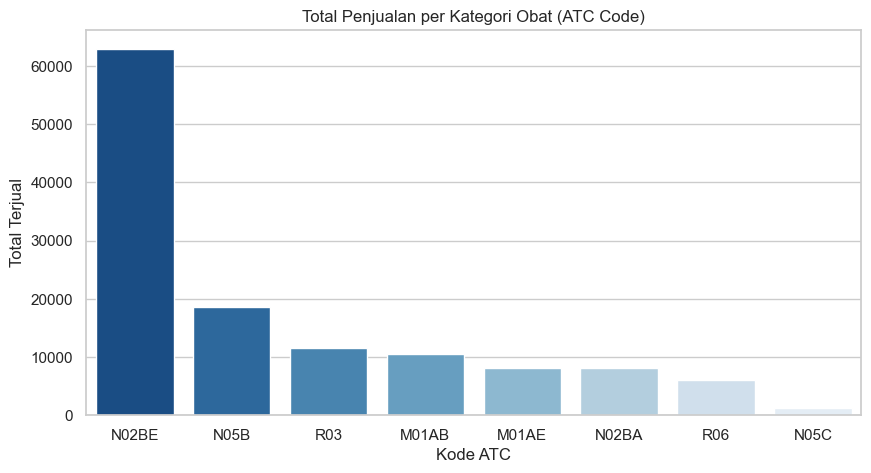

In [3]:
total_sales = df[atc_cols].sum().sort_values(ascending=False)
print("=== Total Penjualan per Kategori ATC ===")
print(total_sales)

print(f"\nObat Terlaris Overall: {total_sales.idxmax()} ({total_sales.max():,.2f} unit)")

# Tampilkan Grafik Bar
plt.figure(figsize=(10, 5))
sns.barplot(x=total_sales.index, y=total_sales.values, palette="Blues_r")
plt.title("Total Penjualan per Kategori Obat (ATC Code)")
plt.xlabel("Kode ATC")
plt.ylabel("Total Terjual")
plt.show()

In [4]:
# Fungsi Top 3
def top_3_in_month(year, month):
    subset = df[(df['datum'].dt.year == year) & (df['datum'].dt.month == month)]
    return subset[atc_cols].sum().nlargest(3)

print("=== Top 3 Obat Januari 2015 ===")
print(top_3_in_month(2015, 1))

print("\n=== Top 3 Obat Juli 2016 ===")
print(top_3_in_month(2016, 7))

print("\n=== Top 3 Obat September 2017 ===")
print(top_3_in_month(2017, 9))

# Top Drug 2017
df_2017 = df[df['datum'].dt.year == 2017]
top_2017 = df_2017[atc_cols].sum().idxmax()
print(f"\nObat Terlaris di Tahun 2017: {top_2017}")

=== Top 3 Obat Januari 2015 ===
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

=== Top 3 Obat Juli 2016 ===
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

=== Top 3 Obat September 2017 ===
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64

Obat Terlaris di Tahun 2017: N02BE


Rata-rata Penjualan Harian Tertinggi: N02BE (29.92 unit/hari)


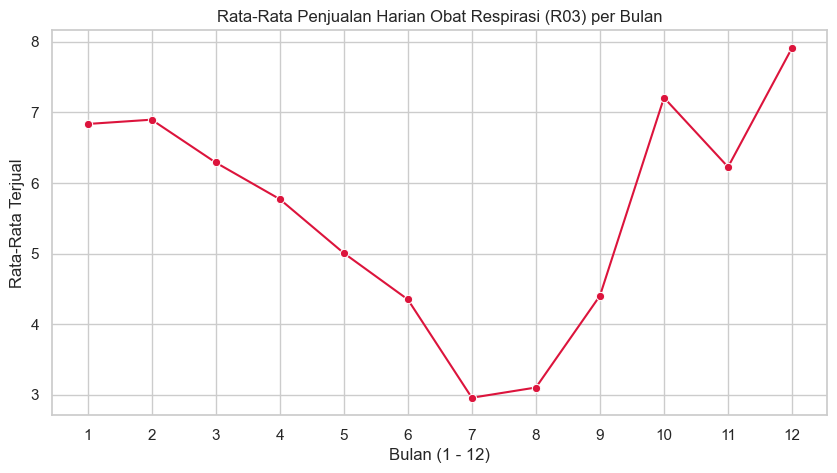

In [5]:
# Rata-rata harian
avg_daily = df[atc_cols].mean().sort_values(ascending=False)
print(f"Rata-rata Penjualan Harian Tertinggi: {avg_daily.idxmax()} ({avg_daily.max():.2f} unit/hari)")

# Musim Obat R03
r03_monthly = df.groupby('Month')['R03'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=r03_monthly.index, y=r03_monthly.values, marker='o', color='crimson')
plt.title("Rata-Rata Penjualan Harian Obat Respirasi (R03) per Bulan")
plt.xlabel("Bulan (1 - 12)")
plt.ylabel("Rata-Rata Terjual")
plt.xticks(range(1, 13))
plt.show()